# Student Performance Initial Exploration
## Project Assignment 02
**Team:** #brokecode  
**Members:** Arnav Chawla, Patrick, Updesh Sachdeva

Our goal is to explore how study time, absences, school educational support, and home internet access relate to final Portuguese-language grades. This milestone includes only loading the data, basic checks, and one visualization. Detailed analysis is planned for the week of October 26, 2026, after midterms.

Dataset: [UCI Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance)  
Cortez, P. (2008). Student Performance. https://doi.org/10.24432/C5TG7T. CC BY 4.0.

We use only `student-por.csv`, which contains student records from two Portuguese schools. `G3` is the final grade on a 0–20 scale. These observational records can show associations, but cannot establish causes.

**Google Colab notebook:** https://colab.research.google.com/drive/1tADW417NLFQEl8PZMlMRxi_1rOAloAw7?usp=sharing

**GitHub repository:** https://github.com/CS122-04-FA26/brokecode-student-performance

**Repository notebook path:** `notebooks/Project_Assignment_02.ipynb`

This is an initial progress milestone, not our final proposal or final analysis. We will improve the questions, methods, visualizations, and timeline as we learn more and receive feedback.

In [1]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

In [3]:
from google.colab import files

uploaded = files.upload()

Saving student-por.csv to student-por.csv


## Load the dataset
We are loading the dataset here.


In [4]:
data_path = Path("student-por.csv")  # Colab session upload
if not data_path.exists():
    data_path = Path("data/student-por.csv")  # Repository root
if not data_path.exists():
    data_path = Path("../data/student-por.csv")  # notebooks folder
if not data_path.exists():
    raise FileNotFoundError("Upload student-por.csv in Colab or place it in data/ locally.")

df = pd.read_csv(data_path, sep=";")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

Rows: 649
Columns: 33


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


## Basic data checks
Check the column types, missing values, and exact duplicate rows before making changes. A zero final grade is a valid value on the stated scale and is retained.

In [5]:
df.info()
print("Missing values:", df.isna().sum().sum())
print("Exact duplicate rows:", df.duplicated().sum())
display(df[["age", "studytime", "absences", "G3"]].describe().round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

,age,studytime,absences,G3
count,649.00,649.00,649.00,649.00
mean,16.74,1.93,3.66,11.91
std,1.22,0.83,4.64,3.23
min,15.00,1.00,0.00,0.00
25%,16.00,1.00,0.00,10.00
50%,17.00,2.00,2.00,12.00
75%,18.00,2.00,6.00,14.00
max,22.00,4.00,32.00,19.00


The file has 649 rows and 33 columns, with no missing values or exact duplicate rows detected. No rows were removed. The `studytime` values are categories: 1 = under 2 hours, 2 = 2–5 hours, 3 = 5–10 hours, and 4 = over 10 hours per week; they are not exact hours.

## First visualization
This histogram shows how final grades are distributed. Each bar represents one grade value.

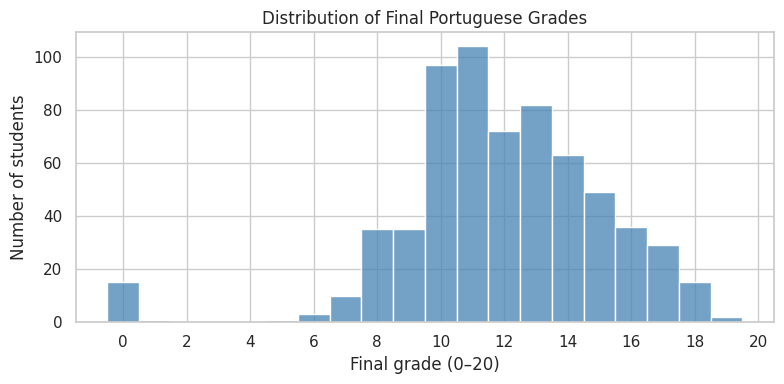

Mean final grade: 11.91
Median final grade: 12.0


In [6]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="G3", discrete=True, color="steelblue")
plt.title("Distribution of Final Portuguese Grades")
plt.xlabel("Final grade (0–20)")
plt.ylabel("Number of students")
plt.xticks(range(0, 21, 2))
plt.tight_layout()
plt.show()

print("Mean final grade:", round(df["G3"].mean(), 2))
print("Median final grade:", df["G3"].median())

## Initial observation and next steps
The mean final grade is 11.91 out of 20 and the median is 12. The distribution gives us a starting point, but it does not explain why students have different grades.

Starting the week of October 26, we plan to:
1. Review the columns and confirm the research questions together.
2. Compare final grades across study-time categories and examine absences.
3. Explore school support and internet-access groups.
4. Select suitable hypothesis tests after reviewing the relevant methods in class.
5. Write the final report, explain limitations, and prepare a presentation if required.

No relationship tests or final conclusions are included in this milestone.